# Extracting Column Data from IFC for Capacity Checks

**Level 1 tutorial · Role: Analyst · Focus area: Structural Analysis · BIM use: 08 Structural Analysis**
Group 24 · Gulshan Kumar, Aida Amirbabaei · Course 41934 Advanced BIM (DTU)

** Building:** DTU Fri is a two-storey extension of DTU Building 308, IFC `26-08-STR.ifc`.

**Objective:** Teach how to read IFC columns, combine retained concrete and its jacket as **one proposed section**, include glulam columns, distribute *synthetic floor loads*, and calculate a simplified **illustrative axial utilization ratio** for each physical column.

> **CRITICAL — NOT A STRUCTURAL SAFETY ASSESSMENT.** In this teaching run, floor regions, structural and occupancy loads, missing section dimensions, missing lengths, material strengths, and load-transfer paths are assumed. The report's nonstructural floor build-up value (0.39 kN/m²) is genuine, but its use over generated synthetic floor regions is NOT the report's actual load case. The program does NOT implement all report load combinations, compression–bending, buckling, composite jacket-interface verification, or real slab/beam load transfer. Every numerical result is marked **DEMO ONLY**. **Not for use it to certify, design, or assess the real building.**

## How to run

1. Keep this Jupyter Notebook and the `data` folder together.

2. Make sure the `data` folder contains the following input files:
   - `26-08-STR.ifc` — Proposed Building 308 structural IFC model.
   - `report_table6_columns_full.csv` — Existing and proposed column dimensions, reinforcement, and jacketing information from the structural report.
   - `report_load_cases.csv` — Loading values extracted from the structural report.
   - `assumptions_DEMO.csv` — Assumed material strengths, load factors, and other parameters used for the teaching calculations.

3. Install the required Python libraries on Windows:

   `py -m pip install notebook ipykernel ifcopenshell numpy pandas matplotlib`

4. Open Command Prompt in the folder containing the notebook and run:

   `py -m notebook`

5. Open the notebook and select **Kernel → Restart Kernel and Run All Cells**.

6. The notebook automatically generates `data/floor_panels_DEMO.csv` using column positions extracted from the IFC model. You do not need to prepare this file manually.

7. The calculated results, including column utilization ratios, are saved in the `results/` folder.

**Folder structure**

  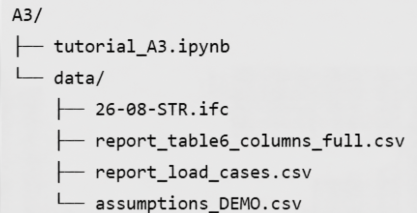

**Important:** The floor regions, several loading assumptions, and some material properties are artificial teaching inputs. Therefore, the calculated utilization ratios are illustrative and do not represent verified structural utilization of Building 308.

## Step 0 — Imports and file locations
The code is for to make every calculation available inside this notebook.

In [1]:
from pathlib import Path
import math
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ifcopenshell

# All Python functions are defined in THIS notebook. No external .py file is used.
ROOT = Path.cwd()
DATA = ROOT / 'data'
OUT = ROOT / 'results'
OUT.mkdir(exist_ok=True)
assert (DATA / '26-08-STR.ifc').is_file(), 'Missing data/26-08-STR.ifc'
print('Input folder:', DATA)
print('MODE: DEMONSTRATION ONLY — invented/assumed loads and properties')

Input folder: D:\DTU\13 week - aug 26\41934\Submission\A3\data
MODE: DEMONSTRATION ONLY — invented/assumed loads and properties


## Step 1 — Read IFC columns

IfcOpenShell reads the IFC as a database (it does not calculate forces). It extract each column’s **GlobalId**, storey, plan location, rectangular section if present, and available length/quantity data. `IfcColumn` also includes **separate jacket objects**, which is not counted as independent load-bearing members.

In [2]:
def profile_dims_m(element, scale):
    import ifcopenshell.util.element as element_util
    typ = element_util.get_type(element)
    reps = (typ.RepresentationMaps or []) if typ is not None else []
    for rep in reps:
        for obj in rep.MappedRepresentation.Items:
            if obj.is_a('IfcExtrudedAreaSolid') and obj.SweptArea.is_a('IfcRectangleProfileDef'):
                p = obj.SweptArea
                return (float(p.XDim)*scale, float(p.YDim)*scale)
    return (np.nan, np.nan)

def extract_columns():
    import ifcopenshell
    import ifcopenshell.util.element as eu
    import ifcopenshell.util.placement as pl
    import ifcopenshell.util.unit as uu
    model = ifcopenshell.open(str(DATA / '26-08-STR.ifc'))
    scale = uu.calculate_unit_scale(model)
    result=[]
    for c in model.by_type('IfcColumn'):
        name=c.Name or ''
        parts=name.split(':')
        family=parts[0]
        if 'Jacketing' in family: kind='jacket_object_not_column'
        elif family.startswith('M_Concrete'): kind='retained_RC'
        elif 'Glulam' in family or 'Timber' in family: kind='new_timber'
        else: kind='unclassified'
        storey=eu.get_container(c,ifc_class='IfcBuildingStorey')
        xyz = pl.get_local_placement(c.ObjectPlacement)[:3,3]*scale if c.ObjectPlacement else [np.nan]*3
        b,h=profile_dims_m(c,scale)
        q=eu.get_psets(c,qtos_only=True).get('Qto_ColumnBaseQuantities',{})
        length=q.get('Length')
        length=float(length)*scale if length is not None else np.nan
        # Do not infer b/h by sqrt(area): this can hide very different sections.
        result.append(dict(GlobalId=c.GlobalId,Name=name,Mark=parts[1] if len(parts)>1 else '',
             Family=family,Kind=kind,Storey=storey.Name if storey else '',
             X_m=float(xyz[0]),Y_m=float(xyz[1]),Z_m=float(xyz[2]),
             IFC_b_mm=b*1000,IFC_h_mm=h*1000,Length_m=length,
             IFC_Quantity_Area_m2=q.get('CrossSectionArea',np.nan)))
    df=pd.DataFrame(result)
    if df.GlobalId.duplicated().any(): raise ValueError('Duplicate IFC GlobalIds')
    df.to_csv(OUT/'all_ifc_column_objects.csv',index=False)
    return df

In [3]:
all_columns = extract_columns()
print('IFC column objects:', len(all_columns))
print(all_columns.Kind.value_counts(dropna=False).to_string())
display(all_columns[
    (all_columns["Storey"] == "E01") &
    (all_columns["Kind"] == "new_timber")
])

IFC column objects: 644
Kind
new_timber                  286
retained_RC                 194
jacket_object_not_column    164


,GlobalId,Name,Mark,Family,Kind,Storey,X_m,Y_m,Z_m,IFC_b_mm,IFC_h_mm,Length_m,IFC_Quantity_Area_m2
0,10fnJPhAr2r8Xrzsgbagw$,Glulam-Square-Column-GL30h:S203.T:1759097,S203.T,Glulam-Square-Column-GL30h,new_timber,E01,0.146186,0.478152,0.0,250.0,250.0,4.22,0.0625
1,10fnJPhAr2r8Xrzsgbag6_,Glulam-Square-Column-GL30h:S202.T:1759352,S202.T,Glulam-Square-Column-GL30h,new_timber,E01,3.206361,-0.457437,0.0,300.0,300.0,4.22,0.0900
2,10fnJPhAr2r8Xrzsgbag54,Glulam-Square-Column-GL30h:S202.T:1759362,S202.T,Glulam-Square-Column-GL30h,new_timber,E01,6.266536,-1.393027,0.0,300.0,300.0,4.22,0.0900
3,10fnJPhAr2r8Xrzsgbag5A,Glulam-Square-Column-GL30h:S202.T:1759372,S202.T,Glulam-Square-Column-GL30h,new_timber,E01,9.326712,-2.328616,0.0,300.0,300.0,4.22,0.0900
4,10fnJPhAr2r8Xrzsgbag5U,Glulam-Square-Column-GL30h:S202.T:1759384,S202.T,Glulam-Square-Column-GL30h,new_timber,E01,12.386887,-3.264205,0.0,300.0,300.0,4.22,0.0900
5,10fnJPhAr2r8Xrzsgbag5Y,Glulam-Square-Column-GL30h:S202.T:1759396,S202.T,Glulam-Square-Column-GL30h,new_timber,E01,15.447062,-4.199795,0.0,300.0,300.0,4.22,0.0900
6,10fnJPhAr2r8Xrzsgbag5s,Glulam-Square-Column-GL30h:S202.T:1759408,S202.T,Glulam-Square-Column-GL30h,new_timber,E01,18.507237,-5.135384,0.0,300.0,300.0,4.22,0.0900
7,10fnJPhAr2r8Xrzsgbag5w,Glulam-Square-Column-GL30h:S202.T:1759420,S202.T,Glulam-Square-Column-GL30h,new_timber,E01,21.567412,-6.070974,0.0,300.0,300.0,4.22,0.0900
8,10fnJPhAr2r8Xrzsgbag4E,Glulam-Square-Column-GL30h:S202.T:1759432,S202.T,Glulam-Square-Column-GL30h,new_timber,E01,24.627588,-7.006563,0.0,300.0,300.0,4.22,0.0900
9,10fnJPhAr2r8Xrzsgbag4I,Glulam-Square-Column-GL30h:S202.T:1759444,S202.T,Glulam-Square-Column-GL30h,new_timber,E01,27.687763,-7.942153,0.0,300.0,300.0,4.22,0.0900


**Try it 1:** Change # Filter columns by floor and type
display(all_columns[
    (all_columns["Storey"] == "E01") &
    (all_columns["Kind"] == "new_timber")
].head(20))

## Step 2 — Proposed Column Dimensions and Reinforcement

In this step, the notebook identifies the proposed dimensions and reinforcement details of the columns in Building 308.

For the existing reinforced-concrete columns, the dimensions and reinforcement are obtained from Table 6 of the structural report. Columns strengthened with concrete jacketing are considered as a single section, including both the original concrete and the jacket.

For the new glulam columns, the cross-sectional dimensions are extracted from the IFC model. Where information is missing, assumed values are used for the demonstration calculations and identified in the results.

Each column is identified by its unique IFC GlobalId, allowing columns with the same structural mark to be considered individually in the subsequent utilization calculations.

In [4]:
def steel_area(rebars):
    matches = re.findall(r'(\d+)\s*[øØϕφ]\s*(\d+(?:\.\d+)?)', str(rebars))
    return sum(int(n) * math.pi * float(d)**2 / 4 for n, d in matches) if matches else np.nan

def proposed_members(all_columns):
    tab=pd.read_csv(DATA/'report_table6_columns_full.csv')
    tab['Mark']=tab.Mark.astype(str)
    if tab.Mark.duplicated().any(): raise ValueError('Table 6 duplicate marks')
    frame=all_columns[all_columns.Kind!='jacket_object_not_column'].copy()
    # Rename before merging: otherwise Length_m becomes Length_m_x/Length_m_y.
    tab=tab.rename(columns={'Length_m':'Report_Length_m'})
    frame=frame.merge(tab,on='Mark',how='left',validate='many_to_one')
    frame['Length_m']=pd.to_numeric(frame['Length_m'],errors='coerce')
    frame['Report_Length_m']=pd.to_numeric(frame['Report_Length_m'],errors='coerce')
    # Report length fallback ONLY for retained RC with corresponding mark.
    is_rc=frame.Kind.eq('retained_RC')
    frame.loc[is_rc,'Length_m']=frame.loc[is_rc,'Length_m'].fillna(frame.loc[is_rc,'Report_Length_m'])
    # use PROPOSED data from report for retained RC; never double-count jacket objects
    rc=frame.Kind=='retained_RC'
    frame['b_mm']=np.where(rc,frame.Proposed_b_mm,frame.IFC_b_mm)
    frame['h_mm']=np.where(rc,frame.Proposed_h_mm,frame.IFC_h_mm)
    frame['Rebars']=np.where(rc,frame.Proposed_Rebars,'')
    frame['As_mm2']=frame.Rebars.map(steel_area)
    frame['Area_mm2']=frame.b_mm*frame.h_mm
    frame['Data_quality']=np.where((frame.Area_mm2>0)&np.isfinite(frame.Area_mm2),'section_present','MISSING_SECTION')
    frame['Length_quality']=np.where(frame.Length_m.notna()&(frame.Length_m>0),'length_present','MISSING_LENGTH')
    frame.loc[rc & frame.Proposed_b_mm.isna(),'Data_quality']='NO_REPORT_MATCH'
    # Demonstration-only section fallbacks; never claim these were documented in IFC/report.
    frame['Demo_assumed_section'] = frame['Area_mm2'].isna() | (frame['Area_mm2'] <= 0)
    frame.loc[frame['Demo_assumed_section'] & frame['b_mm'].isna(), 'b_mm'] = 200.0
    frame.loc[frame['Demo_assumed_section'] & frame['h_mm'].isna(), 'h_mm'] = 200.0
    frame['Area_mm2'] = frame.b_mm * frame.h_mm
    # Missing concrete reinforcement: teaching fallback 4ø16 (not report evidence).
    frame['Demo_assumed_rebars'] = rc & frame.As_mm2.isna()
    frame.loc[frame.Demo_assumed_rebars, 'Rebars'] = '4ø16'
    frame.loc[frame.Demo_assumed_rebars, 'As_mm2'] = steel_area('4ø16')
    # Missing height: choose the IFC storey median, then a 3.5 m teaching default.
    frame['Demo_assumed_length'] = frame.Length_m.isna() | (frame.Length_m <= 0)
    frame['Length_m'] = frame.Length_m.mask(frame.Length_m <= 0)
    frame['Length_m'] = frame['Length_m'].fillna(frame.groupby('Storey')['Length_m'].transform('median')).fillna(3.5)
    frame['Data_quality'] = np.where(frame.Demo_assumed_section,'DEMO_DIMENSION_FALLBACK',frame.Data_quality)
    frame['Length_quality'] = np.where(frame.Demo_assumed_length,'DEMO_LENGTH_FALLBACK',frame.Length_quality)
    frame.to_csv(OUT/'proposed_members.csv',index=False)
    return frame

In [5]:
members = proposed_members(all_columns)
print('IfcColumn objects:', len(all_columns))
print('Jacket objects excluded from independent column count:', int((all_columns.Kind == 'jacket_object_not_column').sum()))
print('Physical column records:', len(members))
print('\nBy material / member type:')
print(members.Kind.value_counts(dropna=False).to_string())
print('\nData checks:')
print(members.Data_quality.value_counts(dropna=False).to_string())
print(members.Length_quality.value_counts(dropna=False).to_string())
display(members[['GlobalId','Mark','Storey','Kind','b_mm','h_mm','Length_m','Rebars','Data_quality','Length_quality']].head(15))
assert members.GlobalId.is_unique
assert not members.Kind.eq('jacket_object_not_column').any()
assert len(all_columns) == len(members) + (all_columns.Kind == 'jacket_object_not_column').sum()

IfcColumn objects: 644
Jacket objects excluded from independent column count: 164
Physical column records: 480

By material / member type:
Kind
new_timber     286
retained_RC    194

Data checks:
Data_quality
section_present            476
DEMO_DIMENSION_FALLBACK      4
Length_quality
length_present    480


,GlobalId,Mark,Storey,Kind,b_mm,h_mm,Length_m,Rebars,Data_quality,Length_quality
0,10fnJPhAr2r8Xrzsgbagw$,S203.T,E01,new_timber,250.0,250.0,4.22,,section_present,length_present
1,10fnJPhAr2r8Xrzsgbag6_,S202.T,E01,new_timber,300.0,300.0,4.22,,section_present,length_present
2,10fnJPhAr2r8Xrzsgbag54,S202.T,E01,new_timber,300.0,300.0,4.22,,section_present,length_present
3,10fnJPhAr2r8Xrzsgbag5A,S202.T,E01,new_timber,300.0,300.0,4.22,,section_present,length_present
4,10fnJPhAr2r8Xrzsgbag5U,S202.T,E01,new_timber,300.0,300.0,4.22,,section_present,length_present
5,10fnJPhAr2r8Xrzsgbag5Y,S202.T,E01,new_timber,300.0,300.0,4.22,,section_present,length_present
6,10fnJPhAr2r8Xrzsgbag5s,S202.T,E01,new_timber,300.0,300.0,4.22,,section_present,length_present
7,10fnJPhAr2r8Xrzsgbag5w,S202.T,E01,new_timber,300.0,300.0,4.22,,section_present,length_present
8,10fnJPhAr2r8Xrzsgbag4E,S202.T,E01,new_timber,300.0,300.0,4.22,,section_present,length_present
9,10fnJPhAr2r8Xrzsgbag4I,S202.T,E01,new_timber,300.0,300.0,4.22,,section_present,length_present


### Check every proposed physical column

The IFC has 194 retained concrete-column objects, 164 separate jacket objects and 286 glulam columns. **Jackets are not counted as extra physical columns.** Columns without documented section dimensions receive a **200 × 200 mm hypothetical demo section**; missing lengths use a storey median or 3.5 m; missing concrete rebars use **4ø16**, each flagged in the output. These assumptions exist ONLY to make every demo calculation runnable.

In [6]:
print('Retained RC proposed members:', (members.Kind == 'retained_RC').sum())
print('New timber members:', (members.Kind == 'new_timber').sum())
print('Other/unclassified members:', (~members.Kind.isin(['retained_RC','new_timber'])).sum())
for kind in ['retained_RC','new_timber']:
    display(members.loc[members.Kind == kind, ['GlobalId','Mark','Storey','b_mm','h_mm','Length_m','Data_quality']].head(5))
print('S102 proposed section (reported):')
display(members.loc[(members.Kind == 'retained_RC') & (members.Mark == 'S102'), ['Mark','b_mm','h_mm','Rebars']].head(3))

Retained RC proposed members: 194
New timber members: 286
Other/unclassified members: 0


,GlobalId,Mark,Storey,b_mm,h_mm,Length_m,Data_quality
21,2BbZXU08z3yu6OLVsU8Sdo,S104,E00,300.0,350.0,3.67,section_present
22,2BbZXU08z3yu6OLVsU8SiN,S108,E00,300.0,400.0,3.10,section_present
23,1rl88_Xoj19fF3qaneO9We,S110,E00,450.0,300.0,3.67,section_present
24,1dhx1CykH8Cf$j9diXrwEu,S102,E00,300.0,300.0,3.67,section_present
25,35se0S21v7su4sD2k8YSPE,S116,E00,200.0,410.0,3.67,section_present


,GlobalId,Mark,Storey,b_mm,h_mm,Length_m,Data_quality
0,10fnJPhAr2r8Xrzsgbagw$,S203.T,E01,250.0,250.0,4.22,section_present
1,10fnJPhAr2r8Xrzsgbag6_,S202.T,E01,300.0,300.0,4.22,section_present
2,10fnJPhAr2r8Xrzsgbag54,S202.T,E01,300.0,300.0,4.22,section_present
3,10fnJPhAr2r8Xrzsgbag5A,S202.T,E01,300.0,300.0,4.22,section_present
4,10fnJPhAr2r8Xrzsgbag5U,S202.T,E01,300.0,300.0,4.22,section_present


S102 proposed section (reported):


,Mark,b_mm,h_mm,Rebars
24,S102,300.0,300.0,6ø25
146,S102,300.0,300.0,6ø25
147,S102,300.0,300.0,6ø25


In [7]:
# Demonstrate one proposed RC section without calculating a structural utilization:
s102 = members[(members.Mark == 'S102') & (members.Kind == 'retained_RC')]
if s102.empty:
    print('S102 not located — inspect IFC marking convention')
else:
    row = s102.iloc[0]
    print(f"S102 proposed gross area: {row.Area_mm2:,.0f} mm²; scheduled reinforcement area: {row.As_mm2:,.1f} mm²")

S102 proposed gross area: 90,000 mm²; scheduled reinforcement area: 2,945.2 mm²


## Step 3 — Simplified Floor Load and Tributary Area Modelling

The report provides nonstructural build-up `0.39 kN/m²` for new floors; other building-area figures are not individual column forces. To make a complete example runnable, **this notebook constructs one invented rectangular floor panel for each occupied IFC column storey**, bounded by its column coordinates. Synthetic structural self-weight and imposed floor loads are assumed. Snow is assigned only to the highest column storey as a demostration scenario. These regions are **not report-specified floor plates** and are not suitable for structural design.

In [8]:
report_actions = pd.read_csv(DATA / 'report_load_cases.csv')
display(report_actions)

# DEMO ONLY: generate one synthetic panel per IFC column storey using column XY extents.
# These bounds and imposed/structural loads are intentionally not claimed to come from the report.
def create_synthetic_floor_panels(members):
    rows = []
    ordered = members.groupby('Storey')['Z_m'].median().sort_values().index.tolist()
    top = ordered[-1] if ordered else None
    for storey in ordered:
        s = members[(members.Storey == storey) & members.X_m.notna() & members.Y_m.notna()]
        if s.empty:
            continue
        xmin,xmax = s.X_m.min()-1.0, s.X_m.max()+1.0
        ymin,ymax = s.Y_m.min()-1.0, s.Y_m.max()+1.0
        if xmax-xmin < 4.0: xmin-=2.0; xmax+=2.0
        if ymax-ymin < 4.0: ymin-=2.0; ymax+=2.0
        rows.append(dict(Panel_ID=f'DEMO_{storey}',Support_storey=storey,
            X_min_m=round(xmin,3),X_max_m=round(xmax,3),
            Y_min_m=round(ymin,3),Y_max_m=round(ymax,3),
            Nonstructural_Gk_kN_m2=0.39, # sourced report figure, assigned to SYNTHETIC zones
            Structural_Gk_kN_m2=2.5,    # INVENTED teaching assumption
            Imposed_Qk_kN_m2=3.0,       # INVENTED teaching assumption
            Snow_Sk_kN_m2=(1.0 if storey==top else 0.0), # INVENTED placement
            Notes='SYNTHETIC floor region; DO NOT USE for building design'))
    panels=pd.DataFrame(rows)
    if panels.empty: raise ValueError('No suitable IFC column storeys/XY positions found')
    panels.to_csv(DATA/'floor_panels_DEMO.csv',index=False)
    return panels

panels_input = create_synthetic_floor_panels(members)
print('Synthetic teaching panels created:',len(panels_input))
display(panels_input)

,Load_case,Description,Characteristic_value,Unit,Source,Limitation
0,new_floor_nonstructural,New floor CLT/concrete non-structural build-up,0.39,kN/m2,3.1 Table 2 PDF p9,excludes structural member self-weight
1,roof_terrace_nonstructural,New rooftop terrace non-structural build-up,0.80,kN/m2,3.1 Table 2 PDF p9,excludes structural member self-weight
2,green_roof_nonstructural,Green roof assembly,1.48,kN/m2,3.1 Table 2 PDF p9,excludes structural member self-weight
3,snow_region_blue,Characteristic snow roof blue regions,1.00,kN/m2,3.3 Figure 9 PDF p10,only designated roof regions
4,snow_region_red,Characteristic snow roof red regions,3.00,kN/m2,3.3 Figure 9 PDF p10,only designated roof regions
5,west_wind_peak_velocity_pressure,Peak velocity pressure west wind,0.60,kN/m2,3.4 PDF p10,NOT a directly applied column force; needs pre...


Synthetic teaching panels created: 4


,Panel_ID,Support_storey,X_min_m,X_max_m,Y_min_m,Y_max_m,Nonstructural_Gk_kN_m2,Structural_Gk_kN_m2,Imposed_Qk_kN_m2,Snow_Sk_kN_m2,Notes
0,DEMO_E00,E00,-3.0,3.000,-3.000,3.000,0.39,2.5,3.0,0.0,SYNTHETIC floor region; DO NOT USE for buildin...
1,DEMO_E01,E01,-1.0,62.158,-19.175,31.684,0.39,2.5,3.0,0.0,SYNTHETIC floor region; DO NOT USE for buildin...
2,DEMO_E02,E02,-1.0,74.488,-19.175,42.618,0.39,2.5,3.0,0.0,SYNTHETIC floor region; DO NOT USE for buildin...
3,DEMO_E03,E03,-1.0,74.488,-19.175,42.618,0.39,2.5,3.0,1.0,SYNTHETIC floor region; DO NOT USE for buildin...


## Step 4 — Approximate load transfer model for column (demonstration only)

In this step, the floor loads estimated in Step 3 are distributed to the nearest columns on each storey. The loads are then transferred to the nearest columns on the floors below.

This simplified approach demonstrates how vertical loads can be distributed through the building. However, it does not account for the actual structural connections, beams, slabs, or load-transfer mechanisms.

In [9]:
def assumptions():
    a = pd.read_csv(DATA / 'assumptions_DEMO.csv', keep_default_na=False)
    return {r.Parameter: (float(r.Value) if r.Value.strip() and r.Parameter != 'glulam_strength_class' else r.Value.strip())
            for r in a.itertuples(index=False)}

def allocate_panels(members, samples_per_axis=25):
    """Allocate each EXPLICIT, user-drawn rectangle by nearest XY member on its
    receiving storey. Cells are a computational proxy, not actual slab/beam supports.
    Separate contributions G (kN), Q (kN), snow (kN). No double-counting areas.
    """
    panels=pd.read_csv(DATA/'floor_panels_DEMO.csv')
    required=['Panel_ID','Support_storey','X_min_m','X_max_m','Y_min_m','Y_max_m',
              'Nonstructural_Gk_kN_m2','Structural_Gk_kN_m2','Imposed_Qk_kN_m2','Snow_Sk_kN_m2']
    if not set(required).issubset(panels.columns): raise ValueError('Missing floor panel input columns')
    loads=members[['GlobalId','Storey']].copy()
    for k in ['Panel_Gk_kN','Panel_Qk_kN','Panel_Sk_kN']:
        loads[k]=0.0
    log=[]
    if panels.empty:
        return loads,panels,pd.DataFrame(log)
    if panels.Panel_ID.duplicated().any(): raise ValueError('Duplicate Panel_ID')
    if panels[required[2:]].isna().any().any(): raise ValueError('Blank panel coordinates or actions: fill explicitly')
    for p in panels.itertuples(index=False):
        eligible=members[(members.Storey==p.Support_storey)&members.X_m.notna()&members.Y_m.notna()]
        if eligible.empty: raise ValueError(f'No columns on panel support storey {p.Support_storey} ({p.Panel_ID})')
        if p.X_max_m<=p.X_min_m or p.Y_max_m<=p.Y_min_m: raise ValueError(f'Invalid panel bounds: {p.Panel_ID}')
        area=(p.X_max_m-p.X_min_m)*(p.Y_max_m-p.Y_min_m)
        xs=p.X_min_m+(np.arange(samples_per_axis)+.5)/samples_per_axis*(p.X_max_m-p.X_min_m)
        ys=p.Y_min_m+(np.arange(samples_per_axis)+.5)/samples_per_axis*(p.Y_max_m-p.Y_min_m)
        xx,yy=np.meshgrid(xs,ys)
        pts=np.c_[xx.ravel(),yy.ravel()]
        centers=eligible[['X_m','Y_m']].to_numpy()
        # small chunks to prevent huge temporary matrices
        closest=[]
        for block in np.array_split(pts,max(1,int(math.ceil(len(pts)/250)))):
            distances=((block[:,None,:]-centers[None,:,:])**2).sum(axis=2)
            closest.extend(np.argmin(distances,axis=1).tolist())
        counts=np.bincount(closest,minlength=len(eligible))
        g=float(p.Nonstructural_Gk_kN_m2)+float(p.Structural_Gk_kN_m2)
        for j,count in enumerate(counts):
            if not count:continue
            gid=eligible.iloc[j].GlobalId
            share=count/len(closest)*area
            ix=loads.index[loads.GlobalId==gid][0]
            loads.at[ix,'Panel_Gk_kN']+=share*g
            loads.at[ix,'Panel_Qk_kN']+=share*float(p.Imposed_Qk_kN_m2)
            loads.at[ix,'Panel_Sk_kN']+=share*float(p.Snow_Sk_kN_m2)
            log.append(dict(Panel_ID=p.Panel_ID,GlobalId=gid,Approx_tributary_area_m2=share,Support_storey=p.Support_storey))
    return loads,panels,pd.DataFrame(log)

def carry_down(members, local, a):
    """Plan-aligned nearest-column vertical transfer estimate.
    WARNING: DOES NOT model beams, cores, transfer girders, slab stiffness, continuity.
    """
    d=members.merge(local.drop(columns='Storey'),on='GlobalId',validate='one_to_one')
    # Length_m is kept unique when the report schedule is merged (Step 2).
    if 'Length_m' not in d.columns:
        raise KeyError('Length_m missing: check Step 2 IFC/report merge')
    density=np.where(d.Kind.eq('retained_RC'),
                     float(a['concrete_density_kN_m3']),
                     float(a['timber_density_kN_m3']))
    d['Column_selfweight_Gk_kN']=(pd.to_numeric(d.Area_mm2,errors='coerce')/1e6
                                     * pd.to_numeric(d.Length_m,errors='coerce') * density)
    d['Selfweight_status']=np.where(d.Column_selfweight_Gk_kN.notna(), 'ESTIMATED', 'MISSING_SECTION_OR_LENGTH')
    d['Local_Gk_kN']=d.Panel_Gk_kN+d.Column_selfweight_Gk_kN
    d['Local_Qk_kN']=d.Panel_Qk_kN
    d['Local_Sk_kN']=d.Panel_Sk_kN
    for typ in ('G','Q','S'):
        d[f'Cumulative_{typ}k_kN']=d[f'Local_{typ}k_kN'].fillna(0)
    storeys=d.groupby('Storey')['Z_m'].median().sort_values(ascending=False)
    names=storeys.index.tolist()
    transfers=[]
    for i in range(len(names)-1):
        upper=d[(d.Storey==names[i])&d.X_m.notna()&d.Y_m.notna()]
        lower=d[(d.Storey==names[i+1])&d.X_m.notna()&d.Y_m.notna()]
        if lower.empty: continue
        lowerxy=lower[['X_m','Y_m']].to_numpy()
        for row in upper.itertuples():
            dist=np.linalg.norm(lowerxy-np.array([row.X_m,row.Y_m]),axis=1)
            j=int(np.argmin(dist))
            if dist[j]>float(a['transfer_max_horizontal_m']):
                transfers.append(dict(Upper=row.GlobalId,Lower='',distance_m=float(dist[j]),Status='NO_ALIGNED_SUPPORT'))
                continue
            target=lower.index[j]
            for typ in ('G','Q','S'):
                d.at[target,f'Cumulative_{typ}k_kN']+=d.at[row.Index,f'Cumulative_{typ}k_kN']
            transfers.append(dict(Upper=row.GlobalId,Lower=d.at[target,'GlobalId'],distance_m=float(dist[j]),Status='APPROX_XY_MATCH'))
    # Even when `local` contains zero placeholders, it has no real floor-panel data.
    d['Has_load_path']=bool((local[['Panel_Gk_kN','Panel_Qk_kN','Panel_Sk_kN']].abs().sum().sum()) > 0)
    d['Load_path_status']=np.where(d.Has_load_path, 'PROXIMITY_APPROXIMATION', 'NO_ASSIGNED_FLOOR_ACTIONS')
    d['Unresolved_transfer_count']=sum(t['Status']=='NO_ALIGNED_SUPPORT' for t in transfers)
    pd.DataFrame(transfers,columns=['Upper','Lower','distance_m','Status']).to_csv(OUT/'approx_vertical_transfer.csv',index=False)
    return d

In [10]:
a = assumptions()
local_loads, specified_panels, audit = allocate_panels(members)
print('Actual floor panels in input:', len(specified_panels))
display(audit.head(10))
loaded_members = carry_down(members, local_loads, a)
display(loaded_members[['GlobalId','Mark','Storey','Kind','Length_m','Selfweight_status',
                        'Local_Gk_kN','Cumulative_Gk_kN','Cumulative_Qk_kN','Cumulative_Sk_kN']].head(12))
if specified_panels.empty:
    print('Floor-panel loads are NOT specified. Any zero load contributions above are placeholders, not a real zero-load result.')

Actual floor panels in input: 4


,Panel_ID,GlobalId,Approx_tributary_area_m2,Support_storey
0,DEMO_E00,2BbZXU08z3yu6OLVsU8Sdo,36.000000,E00
1,DEMO_E01,10fnJPhAr2r8Xrzsgbag6_,41.115555,E01
2,DEMO_E01,10fnJPhAr2r8Xrzsgbag54,82.231110,E01
3,DEMO_E01,10fnJPhAr2r8Xrzsgbag5A,92.509998,E01
4,DEMO_E01,10fnJPhAr2r8Xrzsgbag5U,87.370554,E01
5,DEMO_E01,10fnJPhAr2r8Xrzsgbag5Y,97.649443,E01
6,DEMO_E01,10fnJPhAr2r8Xrzsgbag5s,113.067776,E01
7,DEMO_E01,10fnJPhAr2r8Xrzsgbag5w,102.788887,E01
8,DEMO_E01,10fnJPhAr2r8Xrzsgbag4E,102.788887,E01
9,DEMO_E01,10fnJPhAr2r8Xrzsgbag4I,128.486109,E01


,GlobalId,Mark,Storey,Kind,Length_m,Selfweight_status,Local_Gk_kN,Cumulative_Gk_kN,Cumulative_Qk_kN,Cumulative_Sk_kN
0,10fnJPhAr2r8Xrzsgbagw$,S203.T,E01,new_timber,4.22,ESTIMATED,1.186875,1.186875,0.000000,0.0
1,10fnJPhAr2r8Xrzsgbag6_,S202.T,E01,new_timber,4.22,ESTIMATED,120.533053,120.533053,123.346665,0.0
2,10fnJPhAr2r8Xrzsgbag54,S202.T,E01,new_timber,4.22,ESTIMATED,239.357007,239.357007,246.693329,0.0
3,10fnJPhAr2r8Xrzsgbag5A,S202.T,E01,new_timber,4.22,ESTIMATED,269.062995,269.062995,277.529995,0.0
4,10fnJPhAr2r8Xrzsgbag5U,S202.T,E01,new_timber,4.22,ESTIMATED,254.210001,254.210001,262.111662,0.0
5,10fnJPhAr2r8Xrzsgbag5Y,S202.T,E01,new_timber,4.22,ESTIMATED,283.915990,283.915990,292.948328,0.0
6,10fnJPhAr2r8Xrzsgbag5s,S202.T,E01,new_timber,4.22,ESTIMATED,328.474972,328.474972,339.203327,0.0
7,10fnJPhAr2r8Xrzsgbag5w,S202.T,E01,new_timber,4.22,ESTIMATED,298.768984,298.768984,308.366661,0.0
8,10fnJPhAr2r8Xrzsgbag4E,S202.T,E01,new_timber,4.22,ESTIMATED,298.768984,298.768984,308.366661,0.0
9,10fnJPhAr2r8Xrzsgbag4I,S202.T,E01,new_timber,4.22,ESTIMATED,373.033955,373.033955,385.458327,0.0


## Step 5 — Utilization ratio (all physical proposed columns)

We calculate a simplified axial **utilization ratio** using **assumed** loads, sections (only where absent), strengths and one **assumed load combination**.

**Reinforced concrete:** treat an original + jacketed column as ONE gross proposed section and use the proposed rebar count from Table 6 where available. The simplified formula is **not** a verified composite-section resistance.

**Glulam:** use the IFC section where available and an assumed axial compression strength; buckling and eccentricity are ignored.

> These results are `DEMO ONLY — NOT VERIFIED`, even when below 1.0. No column will be labelled safe or passed. The results can not be reported as the building's actual utilization under the report load combinations.

In [11]:
def calculate_utilization(members, panels, a):
    """Teach an approximate AXIAL ratio only when inputs exist.

    Missing or unverified design inputs => NaN and DATA MISSING status.
    This does not perform a complete EC2/EC5 utilization verification.
    """
    d = members.copy()
    rc = d.Kind.eq('retained_RC')
    timber = d.Kind.eq('new_timber')
    d['N_resistance_axial_estimate_kN'] = np.nan
    d['N_Ed_axial_estimate_kN'] = np.nan
    d['Utilization_ratio'] = np.nan
    d['Assessment_status'] = 'DEMO ONLY — NOT VERIFIED'
    d['Missing_data'] = ''

    has_panels = not panels.empty
    # The report does not contain the complete validated floor-region assignment.
    # Even if panels are supplied, this is a proximity-based loading ESTIMATE.
    missing_rc_strength = [key for key in ('fck_existing_MPa','fck_jacket_MPa',
        'fyk_existing_MPa','fyk_jacket_MPa') if a.get(key,'') == '']
    missing_timber_strength = a.get('glulam_fc0k_MPa','') == ''

    if not missing_rc_strength:
        fcd = float(a['alpha_cc']) * min(float(a['fck_existing_MPa']),
              float(a['fck_jacket_MPa'])) / float(a['gamma_c'])
        fyd = min(float(a['fyk_existing_MPa']),float(a['fyk_jacket_MPa'])) / float(a['gamma_s'])
        applicable = rc & d.Area_mm2.gt(0) & d.As_mm2.ge(0)
        d.loc[applicable,'N_resistance_axial_estimate_kN'] = (
            fcd * (d.loc[applicable,'Area_mm2'] - d.loc[applicable,'As_mm2'])
            + fyd * d.loc[applicable,'As_mm2']) / 1000

    if not missing_timber_strength:
        applicable = timber & d.Area_mm2.gt(0)
        d.loc[applicable,'N_resistance_axial_estimate_kN'] = (
            d.loc[applicable,'Area_mm2'] * float(a['glulam_fc0k_MPa'])
            * float(a['kmod_timber']) / float(a['gamma_M_timber']) / 1000)

    for idx,row in d.iterrows():
        missing=[]
        if not has_panels:
            missing.append('floor loading regions / load paths')
        if pd.isna(row.get('Area_mm2')) or row.Area_mm2 <= 0:
            missing.append('proposed section dimensions')
        if pd.isna(row.get('Length_m')) or row.Length_m <= 0:
            missing.append('column length')
        if row.Kind == 'retained_RC':
            if pd.isna(row.get('As_mm2')):
                missing.append('proposed reinforcement')
            if missing_rc_strength:
                missing.append('RC material strengths: ' + ', '.join(missing_rc_strength))
        elif row.Kind == 'new_timber':
            if missing_timber_strength:
                missing.append('glulam compression strength')
        else:
            missing.append('unclassified physical-column type')
        if row.get('Selfweight_status') != 'ESTIMATED':
            missing.append('self-weight inputs')
        if row.get('Unresolved_transfer_count',0)>0:
            missing.append('unresolved vertical load path')

        # Missing inputs are not replaced with arbitrary numbers.
        if missing:
            d.at[idx,'Assessment_status']='DEMO DATA MISSING'
            d.at[idx,'Missing_data']='; '.join(missing)
            continue
        g,q,s = [row.get(f'Cumulative_{x}k_kN',np.nan) for x in ('G','Q','S')]
        capacity = row['N_resistance_axial_estimate_kN']
        if not all(np.isfinite([g,q,s,capacity])) or capacity <= 0:
            d.at[idx,'Missing_data']='design actions or axial resistance'
            continue
        # DEMONSTRATION combination only; NOT the report's nine combinations.
        ed = max(float(a['gamma_G'])*g + float(a['gamma_Q'])*q
                 + float(a['gamma_S'])*float(a['psi0_snow'])*s,
                 float(a['gamma_G'])*g + float(a['gamma_S'])*s)
        d.at[idx,'N_Ed_axial_estimate_kN']=ed
        d.at[idx,'Utilization_ratio']=ed/capacity
        d.at[idx,'Assessment_status']='DEMO ONLY — NOT VERIFIED'
        d.at[idx,'Missing_data']='Full design verification: governing report load combinations, bending, stability, composite details'

    d['Assessment_limitation'] = (
        'DEMO ONLY with synthetic panels, assumed strengths and dimension fallbacks; not an EC2/EC5 '
        'verified ratio. Beams, walls, slab connectivity, bending, buckling and stages not solved.')
    d.to_csv(OUT/'proposed_all_columns_utilization.csv',index=False)
    return d


In [12]:
result = calculate_utilization(loaded_members, specified_panels, a)
print('Every physical IFC column has an output row:', len(result))
print('Member types:', result.Kind.value_counts(dropna=False).to_dict())
print('Assessment status:')
print(result.Assessment_status.value_counts(dropna=False).to_string())
print('Calculated estimates:', result.Utilization_ratio.notna().sum())
assert set(members.GlobalId) == set(result.GlobalId)
assert result.GlobalId.is_unique
cols = ['GlobalId','Mark','Storey','Kind','b_mm','h_mm','Length_m',
        'N_Ed_axial_estimate_kN','N_resistance_axial_estimate_kN',
        'Utilization_ratio','Assessment_status','Missing_data']
display(result[cols].head(20))
print('Results CSV:', OUT / 'proposed_all_columns_utilization.csv')

print('WARNING: all ratios are made-up-load DEMONSTRATIONS, not Building 308 engineering results.')
print('Columns with assumed section:',int(result.Demo_assumed_section.sum()))
print('Columns with assumed reinforcement:',int(result.Demo_assumed_rebars.sum()))


Every physical IFC column has an output row: 480
Member types: {'new_timber': 286, 'retained_RC': 194}
Assessment status:
Assessment_status
DEMO ONLY — NOT VERIFIED    480
Calculated estimates: 480


,GlobalId,Mark,Storey,Kind,b_mm,h_mm,Length_m,N_Ed_axial_estimate_kN,N_resistance_axial_estimate_kN,Utilization_ratio,Assessment_status,Missing_data
0,10fnJPhAr2r8Xrzsgbagw$,S203.T,E01,new_timber,250.0,250.0,4.22,1.602281,960.0,0.001669,DEMO ONLY — NOT VERIFIED,Full design verification: governing report loa...
1,10fnJPhAr2r8Xrzsgbag6_,S202.T,E01,new_timber,300.0,300.0,4.22,347.739619,1382.4,0.251548,DEMO ONLY — NOT VERIFIED,Full design verification: governing report loa...
2,10fnJPhAr2r8Xrzsgbag54,S202.T,E01,new_timber,300.0,300.0,4.22,693.171953,1382.4,0.501426,DEMO ONLY — NOT VERIFIED,Full design verification: governing report loa...
3,10fnJPhAr2r8Xrzsgbag5A,S202.T,E01,new_timber,300.0,300.0,4.22,779.530037,1382.4,0.563896,DEMO ONLY — NOT VERIFIED,Full design verification: governing report loa...
4,10fnJPhAr2r8Xrzsgbag5U,S202.T,E01,new_timber,300.0,300.0,4.22,736.350995,1382.4,0.532661,DEMO ONLY — NOT VERIFIED,Full design verification: governing report loa...
5,10fnJPhAr2r8Xrzsgbag5Y,S202.T,E01,new_timber,300.0,300.0,4.22,822.709078,1382.4,0.595131,DEMO ONLY — NOT VERIFIED,Full design verification: governing report loa...
6,10fnJPhAr2r8Xrzsgbag5s,S202.T,E01,new_timber,300.0,300.0,4.22,952.246204,1382.4,0.688836,DEMO ONLY — NOT VERIFIED,Full design verification: governing report loa...
7,10fnJPhAr2r8Xrzsgbag5w,S202.T,E01,new_timber,300.0,300.0,4.22,865.888120,1382.4,0.626366,DEMO ONLY — NOT VERIFIED,Full design verification: governing report loa...
8,10fnJPhAr2r8Xrzsgbag4E,S202.T,E01,new_timber,300.0,300.0,4.22,865.888120,1382.4,0.626366,DEMO ONLY — NOT VERIFIED,Full design verification: governing report loa...
9,10fnJPhAr2r8Xrzsgbag4I,S202.T,E01,new_timber,300.0,300.0,4.22,1081.783329,1382.4,0.782540,DEMO ONLY — NOT VERIFIED,Full design verification: governing report loa...


Results CSV: D:\DTU\13 week - aug 26\41934\Submission\A3\results\proposed_all_columns_utilization.csv
Columns with assumed section: 4
Columns with assumed reinforcement: 4


**Try it 2:** Find the highest **demonstration** utilization ratio in `results/proposed_all_columns_utilization.csv`. Which columns have `Demo_assumed_section = True` or `Demo_assumed_rebars = True`?

## Step 6 — Visualize **invented-input utilization examples**

These plotted ratios are results of a assumed loading scenario, not actual engineering demand, and do not represent verified EC2/EC5 checks.

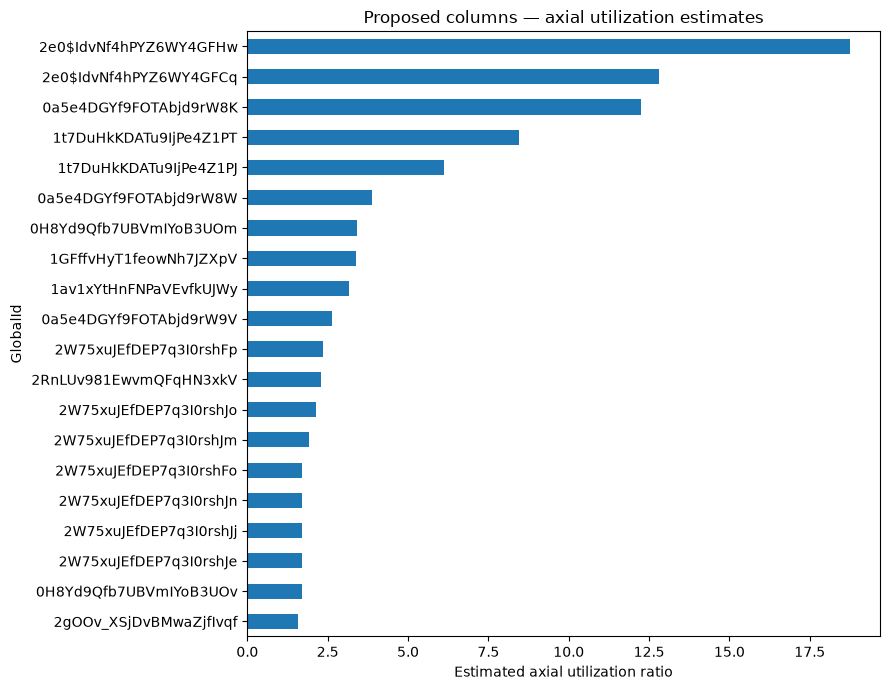

In [13]:
valid = result[result.Utilization_ratio.notna()].copy()
if valid.empty:
    print('Data missing — no utilization ratios can be calculated from the supplied report and inputs.')
    print('See the Missing_data column in proposed_all_columns_utilization.csv.')
else:
    top = valid.nlargest(20,'Utilization_ratio').sort_values('Utilization_ratio')
    ax = top.plot.barh(x='GlobalId',y='Utilization_ratio',legend=False,figsize=(9,7))
    ax.set_xlabel('Estimated axial utilization ratio')
    ax.set_title('Proposed columns — axial utilization estimates')
    plt.tight_layout()
    plt.show()


## Conclusion

This notebook demonstrates the extraction of structural column information from an IFC model, the preparation of proposed cross-sectional properties, and the estimation of column loads and axial utilization ratios using Python.

The analysis considers both retained reinforced-concrete columns and new glulam columns. The loading and resistance calculations are simplified and include assumed parameters. Therefore, the resulting utilization ratios are illustrative and do not represent a complete structural verification of DTU Building 308.